# Ship vs satellite: naive, stratified, border and spectral comparisons

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
import seafloor as sf

lon, lat, z, ship, dx, dy = sf.load_clean()
DX = float(np.mean(dx))
F = sf.compute_features(z, dx, dy)
rough, slope, depth, bpi_b = F[..., 2], F[..., 1], F[..., 0], F[..., 4]
ok = ~np.isnan(F).any(axis=-1)
rng = np.random.default_rng(0)
print(f"Cells: {ok.sum():,}  (ship {(ok & ship).sum():,}, satellite-only {(ok & ~ship).sum():,})")

Cells: 2,485,355  (ship 1,498,911, satellite-only 986,444)


In [2]:
def ratio(a, b): return np.median(b) / np.median(a)

naive = ratio(rough[ok & ship], rough[ok & ~ship])
print(f"Median roughness  ship {np.median(rough[ok & ship]):.1f} m   satellite {np.median(rough[ok & ~ship]):.1f} m   ratio {naive:.2f}")

Median roughness  ship 59.1 m   satellite 41.6 m   ratio 0.70


/tmp/ipykernel_568/710390040.py:1: RuntimeWarning: invalid value encountered in cast
  d_bin = np.floor(depth / 500).astype(int)


Strata with enough ship AND satellite cells: 51  (covering 99% of cells)
Stratified ratio (satellite ÷ ship): 0.89   vs naive 0.70
Strata where satellite is smoother: 75%


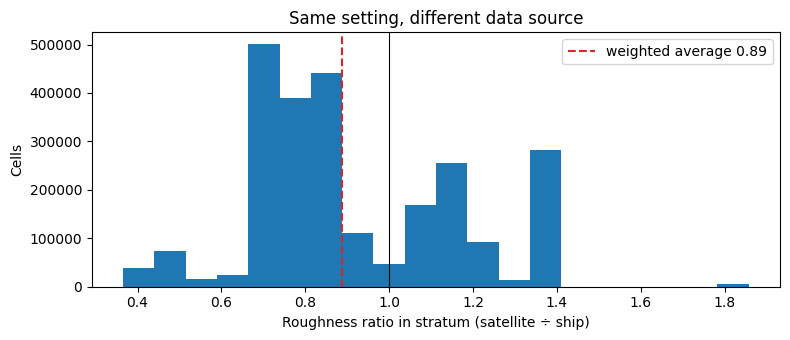

In [3]:
d_bin = np.floor(depth / 500).astype(int)
b_cut = np.nanpercentile(bpi_b[ok], [33, 67])
b_bin = np.digitize(bpi_b, b_cut)
stratum = d_bin * 10 + b_bin

rows = []
for s in np.unique(stratum[ok]):
    m = ok & (stratum == s)
    a, b = rough[m & ship], rough[m & ~ship]
    if len(a) >= 500 and len(b) >= 500:
        rows.append((s, len(a) + len(b), ratio(a, b)))
rows = np.array(rows)
strat = np.exp(np.average(np.log(rows[:, 2]), weights=rows[:, 1]))
print(f"Strata with enough ship AND satellite cells: {len(rows)}  (covering {rows[:, 1].sum() / ok.sum():.0%} of cells)")
print(f"Stratified ratio (satellite ÷ ship): {strat:.2f}   vs naive {naive:.2f}")
print(f"Strata where satellite is smoother: {(rows[:, 2] < 1).mean():.0%}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(rows[:, 2], bins=20, weights=rows[:, 1], color="tab:blue")
ax.axvline(1, c="k", lw=0.8); ax.axvline(strat, c="tab:red", ls="--", label=f"weighted average {strat:.2f}")
ax.set(xlabel="Roughness ratio in stratum (satellite ÷ ship)", ylabel="Cells", title="Same setting, different data source")
ax.legend(); fig.tight_layout(); fig.savefig(sf.FIG_DIR / "06_strata.png", dpi=200); plt.show()

In [4]:
d_bin = np.floor(depth / 500).astype(int)
d_in = ndimage.distance_transform_edt(ship) * DX / 1000
d_out = ndimage.distance_transform_edt(~ship) * DX / 1000
near_in = ok & ship & (d_in >= 3) & (d_in <= 10)
near_out = ok & ~ship & (d_out >= 3) & (d_out <= 10)
border = ratio(rough[near_in], rough[near_out])
print(f"Cells near the border: inside {near_in.sum():,}, outside {near_out.sum():,}")
print(f"Median depth inside {np.median(depth[near_in]):,.0f} m vs outside {np.median(depth[near_out]):,.0f} m")
print(f"Border ratio (satellite ÷ ship): {border:.2f}")

bs = []
for s_ in np.unique(d_bin[near_in | near_out]):
    a_, b_ = rough[near_in & (d_bin == s_)], rough[near_out & (d_bin == s_)]
    if len(a_) >= 300 and len(b_) >= 300: bs.append((len(a_) + len(b_), ratio(a_, b_)))
bs = np.array(bs)
border_strat = np.exp(np.average(np.log(bs[:, 1]), weights=bs[:, 0]))
print(f"Border ratio within depth bands: {border_strat:.2f}  ({len(bs)} bands)")

a, b = rough[near_in], rough[near_out]
boots = [np.median(rng.choice(b, 5000)) / np.median(rng.choice(a, 5000)) for _ in range(500)]
lo_ci, hi_ci = np.percentile(boots, [2.5, 97.5])
print(f"95% bootstrap interval: {lo_ci:.2f} – {hi_ci:.2f}")

/tmp/ipykernel_568/500296512.py:1: RuntimeWarning: invalid value encountered in cast
  d_bin = np.floor(depth / 500).astype(int)


Cells near the border: inside 327,554, outside 160,931
Median depth inside -4,025 m vs outside -4,699 m
Border ratio (satellite ÷ ship): 0.77
Border ratio within depth bands: 0.96  (18 bands)


95% bootstrap interval: 0.73 – 0.80


In [5]:
N = 64
win = np.outer(np.hanning(N), np.hanning(N))
kx, ky = np.meshgrid(np.fft.fftfreq(N, DX), np.fft.fftfreq(N, dy))
K = np.hypot(kx, ky)
edges = np.logspace(np.log10(1.5 / (N * DX)), np.log10(0.5 / min(DX, dy)), 16)
counts = np.array([((K >= edges[i]) & (K < edges[i + 1])).sum() for i in range(len(edges) - 1)])
keep = counts > 0
lo_e, hi_e = edges[:-1][keep], edges[1:][keep]
kc = np.sqrt(lo_e * hi_e); wl_km = 1 / kc / 1000
yy, xx = np.mgrid[:N, :N]; A = np.c_[xx.ravel(), yy.ravel(), np.ones(N * N)]

def spectrum(block):
    coef, *_ = np.linalg.lstsq(A, block.ravel(), rcond=None)
    r = block - (A @ coef).reshape(N, N)
    P = np.abs(np.fft.fft2(r * win)) ** 2
    return np.array([P[(K >= a) & (K < b)].mean() for a, b in zip(lo_e, hi_e)])

spec, blk_depth = {True: [], False: []}, {True: [], False: []}
for i in range(0, z.shape[0] - N, N):
    for j in range(0, z.shape[1] - N, N):
        b = z[i:i+N, j:j+N]; s = ship[i:i+N, j:j+N].mean()
        if np.isnan(b).any() or 0.01 < s < 0.99: continue
        spec[s >= 0.99].append(spectrum(b)); blk_depth[s >= 0.99].append(np.median(b))
S_ship, S_sat = np.log(spec[True]), np.log(spec[False])
print(f"Blocks: ship {len(S_ship)}, satellite-only {len(S_sat)}")
print(f"Median block depth: ship {np.median(blk_depth[True]):,.0f} m, satellite {np.median(blk_depth[False]):,.0f} m")

R = np.exp(S_sat.mean(0) - S_ship.mean(0))
boot = np.array([np.exp(S_sat[rng.integers(0, len(S_sat), len(S_sat))].mean(0)
                        - S_ship[rng.integers(0, len(S_ship), len(S_ship))].mean(0)) for _ in range(1000)])
R_lo, R_hi = np.percentile(boot, [2.5, 97.5], axis=0)

half = wl_km[np.argmax(R < 0.5)] if (R < 0.5).any() else np.nan
print(f"\n{'wavelength':>11s} {'ratio':>7s}   95% interval")
for w_, r_, l_, h_ in zip(wl_km, R, R_lo, R_hi): print(f"{w_:8.1f} km {r_:7.2f}   {l_:.2f}–{h_:.2f}")
print(f"\nSatellite-only seafloor has less than half the ship-measured detail below ≈ {half:.1f} km wavelength")

Blocks: ship 191, satellite-only 139
Median block depth: ship -4,460 m, satellite -4,636 m



 wavelength   ratio   95% interval
    15.0 km    1.02   0.62–1.72
    10.0 km    0.86   0.54–1.40
     8.1 km    0.70   0.44–1.13
     6.6 km    0.68   0.45–1.07
     5.4 km    0.62   0.41–0.96
     4.4 km    0.55   0.36–0.85
     3.6 km    0.44   0.29–0.68
     2.9 km    0.35   0.23–0.54
     2.4 km    0.30   0.20–0.47
     2.0 km    0.25   0.16–0.40
     1.6 km    0.24   0.16–0.38
     1.3 km    0.24   0.16–0.37
     1.1 km    0.26   0.18–0.40

Satellite-only seafloor has less than half the ship-measured detail below ≈ 3.6 km wavelength


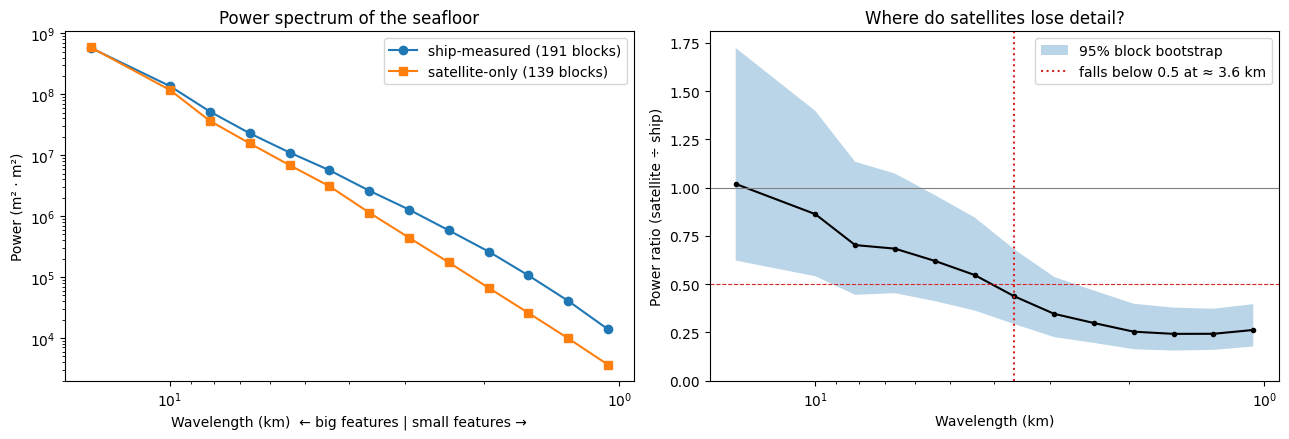

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].loglog(wl_km, np.exp(S_ship.mean(0)), "o-", label=f"ship-measured ({len(S_ship)} blocks)")
axes[0].loglog(wl_km, np.exp(S_sat.mean(0)), "s-", label=f"satellite-only ({len(S_sat)} blocks)")
axes[0].invert_xaxis(); axes[0].set(xlabel="Wavelength (km)  ← big features | small features →", ylabel="Power (m² · m²)",
                                    title="Power spectrum of the seafloor"); axes[0].legend()
axes[1].semilogx(wl_km, R, "k.-"); axes[1].fill_between(wl_km, R_lo, R_hi, alpha=0.3, label="95% block bootstrap")
axes[1].axhline(1, c="gray", lw=0.8); axes[1].axhline(0.5, c="tab:red", ls="--", lw=0.8)
if np.isfinite(half): axes[1].axvline(half, c="tab:red", ls=":", label=f"falls below 0.5 at ≈ {half:.1f} km")
axes[1].invert_xaxis(); axes[1].set(xlabel="Wavelength (km)", ylabel="Power ratio (satellite ÷ ship)",
                                    title="Where do satellites lose detail?", ylim=(0, max(1.5, R_hi.max() * 1.05))); axes[1].legend()
fig.tight_layout(); fig.savefig(sf.FIG_DIR / "06_spectrum.png", dpi=200); plt.show()

In [7]:
print("KEY NUMBERS")
print(f"  Roughness ratio satellite ÷ ship: naive {naive:.2f} | stratified {strat:.2f} | border {border:.2f} "
      f"(95% CI {lo_ci:.2f}–{hi_ci:.2f}) | border within depth bands {border_strat:.2f}")
print(f"  Spectral blocks: ship {len(S_ship)}, satellite {len(S_sat)}")
i_long, i_short = np.argmax(wl_km), np.argmin(wl_km)
print(f"  Power ratio at {wl_km[i_long]:.0f} km: {R[i_long]:.2f};  at {wl_km[i_short]:.1f} km: {R[i_short]:.2f}")
print(f"  Satellite detail drops below half at ≈ {half:.1f} km wavelength")

KEY NUMBERS
  Roughness ratio satellite ÷ ship: naive 0.70 | stratified 0.89 | border 0.77 (95% CI 0.73–0.80) | border within depth bands 0.96
  Spectral blocks: ship 191, satellite 139
  Power ratio at 15 km: 1.02;  at 1.1 km: 0.26
  Satellite detail drops below half at ≈ 3.6 km wavelength
